# Accountant Validation

This notebook validates the `AdaptiveTCTAccountant` and `StandardIDPAccountant` implementations before running the main experiments.

**Sections:**
1. Math primitives — α(i) schedule and prepaid compositions K_k
2. Per-user charging — how a single user's budget is consumed under each accountant
3. Telescoping invariant — empirical verification that total ε charged after k hits = K_{k+1}·ε
4. Simulation comparison — TCT vs IDP user retention and budget consumption

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import matplotlib.pyplot as plt

from simulation.population import User, UserPopulation
from simulation.accountants.adaptive_tct import AdaptiveTCTAccountant
from simulation.accountants.standard_idp import StandardIDPAccountant
from simulation.datasets import generate_synthetic_population, PopulationConfig
from simulation.environment import SimulationEnvironment

plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})

## Section 1: Math Primitives

Verify the dynamic alpha schedule (Theorem 3, Zeta-2 allocation) and prepaid composition count K_k.

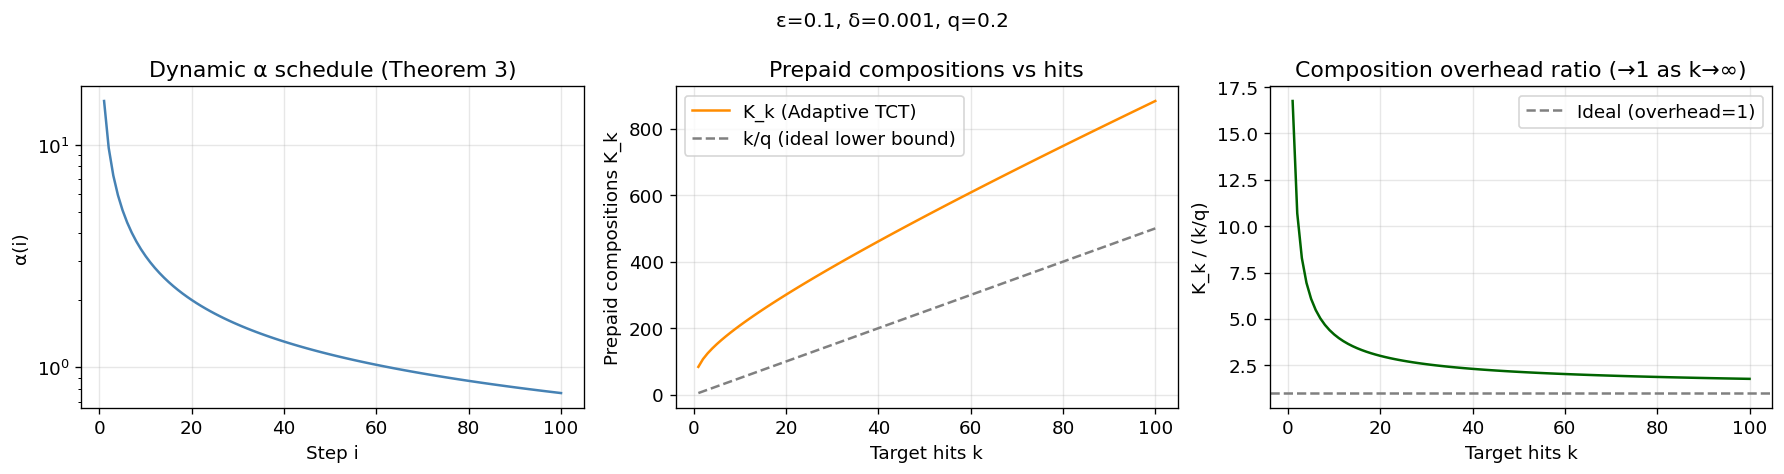

K_1 (registration cost in compositions): 83.756
Registration ε cost (K_1·ε):             8.3756
Break-even with IDP (K_1 rounds):         83.8


In [2]:
# Parameters to explore
EPSILON = 0.1
DELTA   = 1e-3
Q       = 0.2

tct = AdaptiveTCTAccountant(epsilon=EPSILON, delta=DELTA, q=Q)

i_vals = np.arange(1, 101)
alpha_vals = [tct.alpha(i) for i in i_vals]
K_vals     = [tct.compositions(k) for k in i_vals]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Alpha schedule
ax = axes[0]
ax.plot(i_vals, alpha_vals, color='steelblue')
ax.set_xlabel('Step i')
ax.set_ylabel('α(i)')
ax.set_title('Dynamic α schedule (Theorem 3)')
ax.set_yscale('log')
ax.grid(True, alpha=0.3)

# Prepaid compositions K_k
ax = axes[1]
ax.plot(i_vals, K_vals, color='darkorange', label='K_k (Adaptive TCT)')
ax.plot(i_vals, i_vals / Q, color='gray', linestyle='--', label='k/q (ideal lower bound)')
ax.set_xlabel('Target hits k')
ax.set_ylabel('Prepaid compositions K_k')
ax.set_title('Prepaid compositions vs hits')
ax.legend()
ax.grid(True, alpha=0.3)

# Overhead ratio K_k / (k/q)
ax = axes[2]
overhead = [K_vals[i] / (i_vals[i] / Q) for i in range(len(i_vals))]
ax.plot(i_vals, overhead, color='darkgreen')
ax.axhline(1.0, color='gray', linestyle='--', label='Ideal (overhead=1)')
ax.set_xlabel('Target hits k')
ax.set_ylabel('K_k / (k/q)')
ax.set_title('Composition overhead ratio (→1 as k→∞)')
ax.legend()
ax.grid(True, alpha=0.3)

plt.suptitle(f'ε={EPSILON}, δ={DELTA}, q={Q}', fontsize=12)
plt.tight_layout()
plt.show()

print(f'K_1 (registration cost in compositions): {tct.compositions(1):.3f}')
print(f'Registration ε cost (K_1·ε):             {tct.compositions(1)*EPSILON:.4f}')
print(f'Break-even with IDP (K_1 rounds):         {tct.compositions(1):.1f}')

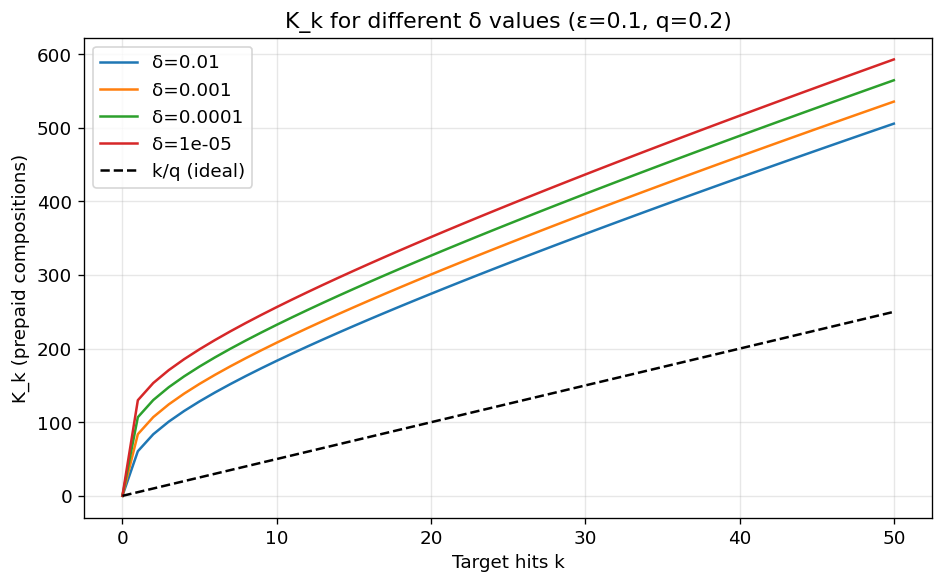

In [3]:
# Compare K_k across different delta values
deltas = [1e-2, 1e-3, 1e-4, 1e-5]
k_vals_range = np.arange(0, 51)

fig, ax = plt.subplots(figsize=(8, 5))
for d in deltas:
    t = AdaptiveTCTAccountant(epsilon=EPSILON, delta=d, q=Q)
    Ks = [t.compositions(k) for k in k_vals_range]
    ax.plot(k_vals_range, Ks, label=f'δ={d}')

ax.plot(k_vals_range, k_vals_range / Q, 'k--', label='k/q (ideal)')
ax.set_xlabel('Target hits k')
ax.set_ylabel('K_k (prepaid compositions)')
ax.set_title(f'K_k for different δ values (ε={EPSILON}, q={Q})')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Section 2: Per-User Charging Behavior

Trace how a single user's epsilon budget is consumed under Adaptive TCT vs Standard IDP.
TCT charges only at registration and on target hits; IDP charges every round.

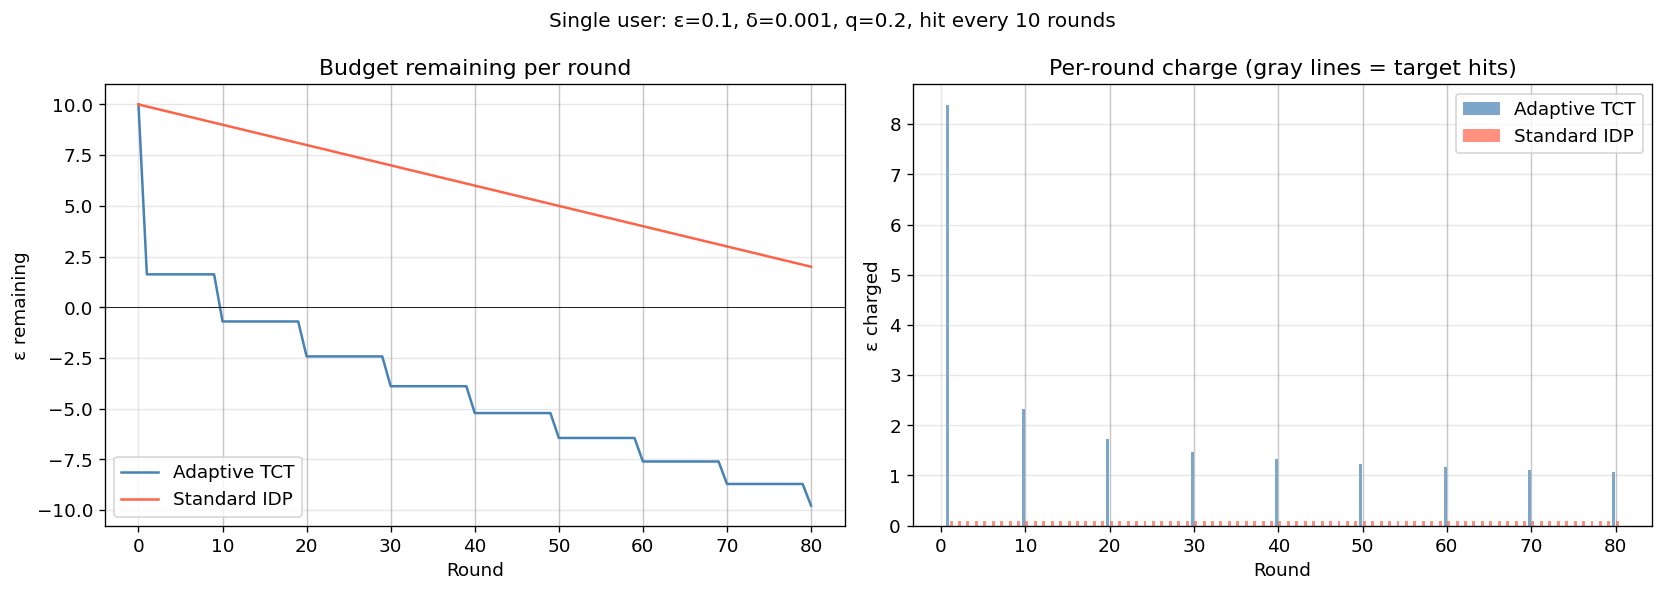

TCT total ε spent:  19.7759
IDP total ε spent:  8.0000
TCT cx (hit count): 9


In [4]:
EPSILON    = 0.1
DELTA      = 1e-3
Q          = 0.2
EPS_BUDGET = 10.0
N_ROUNDS   = 80
HIT_EVERY  = 10  # simulate a hit every 10 rounds (empirical hit rate ≈ q = 0.1)

tct = AdaptiveTCTAccountant(epsilon=EPSILON, delta=DELTA, q=Q)
idp = StandardIDPAccountant(epsilon_per_round=EPSILON, delta_per_round=0.0)

user_tct = User(user_id=0, epsilon_budget=EPS_BUDGET, delta_budget=1.0, conversion_rate=Q)
user_idp = User(user_id=1, epsilon_budget=EPS_BUDGET, delta_budget=1.0, conversion_rate=Q)

tct_remaining = [EPS_BUDGET]
idp_remaining = [EPS_BUDGET]
tct_charges   = []
idp_charges   = []
hit_rounds    = []

for r in range(1, N_ROUNDS + 1):
    is_top = (r % HIT_EVERY == 0)
    if is_top:
        hit_rounds.append(r)

    tct_eps, _ = tct.charge(user_tct, is_top=is_top, contributed=is_top, round_num=r)
    idp_eps, _ = idp.charge(user_idp, is_top=is_top, contributed=is_top, round_num=r)

    user_tct.epsilon_spent += tct_eps
    user_idp.epsilon_spent += idp_eps

    tct_remaining.append(user_tct.epsilon_remaining)
    idp_remaining.append(user_idp.epsilon_remaining)
    tct_charges.append(tct_eps)
    idp_charges.append(idp_eps)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Budget remaining
ax = axes[0]
ax.plot(range(N_ROUNDS + 1), tct_remaining, color='steelblue', label='Adaptive TCT')
ax.plot(range(N_ROUNDS + 1), idp_remaining, color='tomato', label='Standard IDP')
for h in hit_rounds:
    ax.axvline(h, color='gray', alpha=0.3, linewidth=0.8)
ax.axhline(0, color='black', linewidth=0.5)
ax.set_xlabel('Round')
ax.set_ylabel('ε remaining')
ax.set_title('Budget remaining per round')
ax.legend()
ax.grid(True, alpha=0.3)

# Per-round charge
ax = axes[1]
rounds = range(1, N_ROUNDS + 1)
ax.bar([r - 0.2 for r in rounds], tct_charges, width=0.35, color='steelblue', alpha=0.7, label='Adaptive TCT')
ax.bar([r + 0.2 for r in rounds], idp_charges, width=0.35, color='tomato', alpha=0.7, label='Standard IDP')
ax.set_xlabel('Round')
ax.set_ylabel('ε charged')
ax.set_title('Per-round charge (gray lines = target hits)')
ax.legend()
ax.grid(True, alpha=0.3)
for h in hit_rounds:
    ax.axvline(h, color='gray', alpha=0.3, linewidth=0.8)

plt.suptitle(f'Single user: ε={EPSILON}, δ={DELTA}, q={Q}, hit every {HIT_EVERY} rounds', fontsize=12)
plt.tight_layout()
plt.show()

print(f'TCT total ε spent:  {user_tct.epsilon_spent:.4f}')
print(f'IDP total ε spent:  {user_idp.epsilon_spent:.4f}')
print(f'TCT cx (hit count): {tct.hit_count(0)}')

## Section 3: Telescoping Invariant

Theorem 5 requires that after k actual target hits, the IDP filter has charged exactly K_{k+1}·ε.
This section verifies that invariant empirically and plots the stepwise charge progression.

In [ ]:
EPSILON = 0.1
DELTA   = 1e-3
Q       = 0.2
MAX_K   = 20

def simulate_k_hits(k, epsilon=EPSILON, delta=DELTA, q=Q):
    """Simulate exactly k hits on a fresh accountant. Return total (eps, delta) charged."""
    tct  = AdaptiveTCTAccountant(epsilon=epsilon, delta=delta, q=q)
    user = User(user_id=0, epsilon_budget=1e9, delta_budget=1.0, conversion_rate=q)
    total_eps = 0.0
    total_delta = 0.0
    # Round 1: registration (not a hit)
    e, d = tct.charge(user, is_top=False, contributed=False, round_num=1)
    total_eps += e; total_delta += d
    # k hits
    for hit in range(1, k + 1):
        e, d = tct.charge(user, is_top=True, contributed=True, round_num=hit + 1)
        total_eps += e; total_delta += d
    return total_eps, total_delta

k_range = range(0, MAX_K + 1)
empirical_eps   = []
theoretical_eps = []
errors          = []

tct_ref = AdaptiveTCTAccountant(epsilon=EPSILON, delta=DELTA, q=Q)

for k in k_range:
    emp_e, _ = simulate_k_hits(k)
    # After k hits, should equal K_{k+1} * epsilon (Theorem 5)
    theo_e = tct_ref.compositions(k + 1) * EPSILON
    empirical_eps.append(emp_e)
    theoretical_eps.append(theo_e)
    errors.append(abs(emp_e - theo_e))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
ax.plot(k_range, theoretical_eps, 'o-', color='steelblue', label='Theoretical K_{k+1}·ε')
ax.plot(k_range, empirical_eps,   'x--', color='tomato',    label='Empirical total ε charged', markersize=8)
ax.set_xlabel('Actual target hits k')
ax.set_ylabel('Cumulative ε charged')
ax.set_title('Telescoping invariant: empirical vs theoretical')
ax.legend()
ax.grid(True, alpha=0.3)

ax = axes[1]
ax.semilogy(k_range, [max(e, 1e-16) for e in errors], 'o-', color='darkgreen')
ax.set_xlabel('Actual target hits k')
ax.set_ylabel('|empirical − theoretical| (log scale)')
ax.set_title('Telescoping error (should be ≈ floating point noise)')
ax.grid(True, alpha=0.3)

plt.suptitle(f'Telescoping invariant: ε={EPSILON}, δ={DELTA}, q={Q}', fontsize=12)
plt.tight_layout()
plt.show()

max_err = max(errors)
print(f'Max absolute error across k=0..{MAX_K}: {max_err:.2e}')
print('PASS' if max_err < 1e-10 else f'FAIL — max error {max_err:.2e} exceeds 1e-10')

## Section 4: Simulation Comparison

Run a full simulation with both accountants and compare:
- User retention (fraction of users with budget remaining)
- Average epsilon remaining over rounds

In [ ]:
# Simulation parameters
# TCT registration cost = K_1 * epsilon = ((1+alpha_1)/q) * epsilon
# With q=0.3, delta=1e-3, epsilon=0.1: K_1 ≈ 55.8, registration ≈ 5.58ε
# IDP depletes at round eps_budget/epsilon = 150; TCT users survive with ~9.4ε remaining
N_USERS      = 500
N_ROUNDS     = 300
EPSILON      = 0.1
DELTA        = 1e-3
Q            = 0.3     # target noisy hit rate — passed to the TCT accountant
EPS_BUDGET   = 15.0
DELTA_BUDGET = 1.0
SEED         = 42

# Generate BOTH populations from the same seed so they are identical.
config = PopulationConfig(
    n_users=N_USERS, alpha=0.3, beta=0.7,
    epsilon_budget=EPS_BUDGET, delta_budget=DELTA_BUDGET
)
pop_tct = generate_synthetic_population(config, rng=np.random.default_rng(SEED))
pop_idp = generate_synthetic_population(config, rng=np.random.default_rng(SEED))

# Calibrate threshold T on the NOISY count distribution.
#
# q in the TCT paper is P(true_count + Lap(1/ε) ≥ T) — it covers the joint
# randomness of user behavior AND Laplace noise. Using the noiseless (1-Q)
# quantile underestimates q by a factor of 1.6–4.8×, inflating K_k and
# degrading the tightness of the H2 bound. Correct calibration must use the
# noisy distribution.
from simulation.calibration import calibrate_threshold

calib_pop = generate_synthetic_population(config, rng=np.random.default_rng(SEED))
THRESHOLD, q_empirical = calibrate_threshold(
    population=calib_pop,
    epsilon=EPSILON,
    target_q=Q,
    n_pilot=2000,
    rng=np.random.default_rng(999),
)

tct_ref = AdaptiveTCTAccountant(EPSILON, DELTA, Q)
print(f'Threshold T (noisy (1-Q) quantile):  {THRESHOLD:.2f}')
print(f'Pilot noisy hit rate:                {q_empirical:.3f}  (target Q={Q})')
print()
print(f'K_1 (registration compositions):     {tct_ref.compositions(1):.1f}')
print(f'Registration ε cost (K_1·ε):         {tct_ref.compositions(1)*EPSILON:.3f}')
print(f'IDP depletion round (budget/ε):      {EPS_BUDGET/EPSILON:.0f}')

In [ ]:
# Run Adaptive TCT simulation
accountant_tct = AdaptiveTCTAccountant(epsilon=EPSILON, delta=DELTA, q=Q)
env_tct = SimulationEnvironment(
    population=pop_tct,
    accountant=accountant_tct,
    threshold=THRESHOLD,
    query_epsilon=EPSILON,
    num_rounds=N_ROUNDS,
    rng=np.random.default_rng(SEED),
)
result_tct = env_tct.run()

# Run Standard IDP simulation
accountant_idp = StandardIDPAccountant(epsilon_per_round=EPSILON, delta_per_round=0.0)
env_idp = SimulationEnvironment(
    population=pop_idp,
    accountant=accountant_idp,
    threshold=THRESHOLD,
    query_epsilon=EPSILON,
    num_rounds=N_ROUNDS,
    rng=np.random.default_rng(SEED),
)
result_idp = env_idp.run()

print(f'TCT: {len(result_tct.rounds)} rounds completed, {result_tct.total_queries_answered} queries answered')
print(f'IDP: {len(result_idp.rounds)} rounds completed, {result_idp.total_queries_answered} queries answered')

In [ ]:
# Plot comparison
tct_active   = result_tct.active_fraction_by_round()
idp_active   = result_idp.active_fraction_by_round()
tct_avg_eps  = result_tct.avg_epsilon_remaining_by_round()
idp_avg_eps  = result_idp.avg_epsilon_remaining_by_round()

rounds_tct = list(range(len(tct_active)))
rounds_idp = list(range(len(idp_active)))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# User retention
ax = axes[0]
ax.plot(rounds_tct, tct_active, color='steelblue', linewidth=2, label='Adaptive TCT')
ax.plot(rounds_idp, idp_active, color='tomato',    linewidth=2, label='Standard IDP')
ax.set_xlabel('Round')
ax.set_ylabel('Fraction of users active')
ax.set_title('User Retention Curve')
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(True, alpha=0.3)

# Average epsilon remaining
ax = axes[1]
ax.plot(rounds_tct, tct_avg_eps, color='steelblue', linewidth=2, label='Adaptive TCT')
ax.plot(rounds_idp, idp_avg_eps, color='tomato',    linewidth=2, label='Standard IDP')
ax.axhline(0, color='black', linewidth=0.5)
ax.set_xlabel('Round')
ax.set_ylabel('Avg ε remaining (active users)')
ax.set_title('Average Budget Remaining')
ax.legend()
ax.grid(True, alpha=0.3)

plt.suptitle(
    f'N={N_USERS}, ε={EPSILON}, δ={DELTA}, q={Q}, T={THRESHOLD}, budget={EPS_BUDGET}',
    fontsize=11
)
plt.tight_layout()
plt.show()

print(f'TCT final active fraction: {tct_active[-1]:.3f}')
print(f'IDP final active fraction: {idp_active[-1]:.3f}')
print(f'TCT final avg ε remaining: {tct_avg_eps[-1]:.4f}')
print(f'IDP final avg ε remaining: {idp_avg_eps[-1]:.4f}')

In [ ]:
# Top round analysis — what fraction of rounds crossed the threshold?
top_rounds_tct = result_tct.top_rounds()
top_rounds_idp = result_idp.top_rounds()

empirical_hit_rate_tct = result_tct.empirical_hit_rate()
empirical_hit_rate_idp = result_idp.empirical_hit_rate()

print(f'Target hit rounds (TCT sim): {len(top_rounds_tct)} / {len(result_tct.rounds)}  ({empirical_hit_rate_tct:.3f})')
print(f'Target hit rounds (IDP sim): {len(top_rounds_idp)} / {len(result_idp.rounds)}  ({empirical_hit_rate_idp:.3f})')
print(f'Configured q: {Q}')
print()
print(f'TCT cx distribution (prepaid hit counts):')
cx_counts = {}
for uid in range(min(N_USERS, 10)):
    cx = accountant_tct.hit_count(uid)
    cx_counts[cx] = cx_counts.get(cx, 0) + 1
print(f'  (first 10 users) cx values:', [accountant_tct.hit_count(uid) for uid in range(min(N_USERS, 10))])